# 중간고사 기초 · 이론을 코드로 적용하기
시험 목적: **기초 이론을 실제 코드에 적용하는 프로그래밍 능력 평가**

기초 30문제입니다. 기존 14개 데이터셋 실습에 앞서 연습하세요.
각 문제는 **문제 설명 1셀 + 코드 1셀**이며 공통 준비 셀 이후 개별 실행할 수 있습니다.
수식·규칙을 NumPy 또는 TensorFlow 코드로 작성하고 숫자·shape·그래프로 확인합니다.
입력은 문제 안에 주어진 작은 계산 예시입니다. 외부 데이터셋이나 CSV가 필요하지 않습니다.

허용 도구는 공통 준비 셀의 라이브러리입니다. 직접 계산을 요구한 문제는 완성된 지표 함수 대신 식을 구현하세요.
형태·계산·업데이트 규칙이 맞는지 확인하는 연습이며 최고 정확도를 요구하지 않습니다.

**정답용:** 모든 코드 셀을 직접 실행하여 출력과 그래프를 저장했습니다.


## 공통 준비


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    BatchNormalization,
    LayerNormalization,
)
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.regularizers import l1, l2

keras.utils.set_random_seed(42)
np.set_printoptions(precision=4, suppress=True)
print("NumPy:", np.__version__, "| TensorFlow:", tf.__version__)


NumPy: 2.5.4 | TensorFlow: 2.21.0


## 기초 문제 1. 배열 shape, reshape, slicing

**관련 강의:** L02

1. 0~11 배열을 (3,4)로 바꾸고 전치 배열의 shape를 출력하세요.
2. 첫 두 행의 마지막 두 열과, 축을 유지한 첫 번째 열을 꺼내세요.


In [2]:
values = np.arange(12)
X = values.reshape(3, 4)
X_transpose = X.T
part = X[:2, -2:]
first_column = X[:, 0:1]  # (3,)이 아닌 (3,1)을 유지합니다.
print("X / transpose:", X.shape, X_transpose.shape)
print("Selected block:", part)
print("First column shape:", first_column.shape)
assert X.shape == (3, 4) and X_transpose.shape == (4, 3)
np.testing.assert_array_equal(part, [[2, 3], [6, 7]])
assert first_column.shape == (3, 1)


X / transpose: (3, 4) (4, 3)
Selected block: [[2 3]
 [6 7]]
First column shape: (3, 1)


## 기초 문제 2. 내적과 외적

**관련 강의:** L02

1. 두 벡터의 내적과 외적을 계산하세요.
2. 각 결과의 값과 shape를 출력하세요.


In [3]:
x = np.array([1, 2, 3])
y = np.array([4, 5, 6])
dot = np.dot(x, y)
outer = np.outer(x, y)
print("Dot:", dot, "shape:", np.shape(dot))
print("Outer:", outer, "shape:", outer.shape)
assert dot == 32 and outer.shape == (3, 3)
np.testing.assert_array_equal(outer[1], [8, 10, 12])


Dot: 32 shape: ()
Outer: [[ 4  5  6]
 [ 8 10 12]
 [12 15 18]] shape: (3, 3)


## 기초 문제 3. 행렬 곱과 원소별 곱

**관련 강의:** L02

1. A @ B와 A * B를 각각 계산하고 출력하세요.
2. 행렬 곱 첫 원소가 19가 되는 계산을 코드로 확인하세요.


In [4]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])
matrix_product = A @ B
element_product = A * B
print("Matrix product:", matrix_product)
print("Element-wise product:", element_product)
print("First matrix element:", np.sum(A[0, :] * B[:, 0]))
np.testing.assert_array_equal(matrix_product, [[19, 22], [43, 50]])
np.testing.assert_array_equal(element_product, [[5, 12], [21, 32]])


Matrix product: [[19 22]
 [43 50]]
Element-wise product: [[ 5 12]
 [21 32]]
First matrix element: 19


## 기초 문제 4. Broadcasting과 특성 연결

**관련 강의:** L02

1. (4,3) 입력의 모든 행에 같은 bias 벡터를 더하세요.
2. 1로 채운 특성 열 1개와, 0으로 채운 샘플 행 1개를 각각 연결해 shape를 출력하세요.


In [5]:
X = np.arange(12).reshape(4, 3).astype(float)
bias = np.array([0.1, 0.2, 0.3])
shifted = X + bias  # (3,) 벡터를 각 행에 적용합니다.
extra_feature = np.concatenate([X, np.ones((4, 1))], axis=1)
extra_sample = np.concatenate([X, np.zeros((1, 3))], axis=0)
print("Bias added:", shifted)
print("Feature / sample concatenation:", extra_feature.shape, extra_sample.shape)
np.testing.assert_allclose(shifted - X, np.broadcast_to(bias, X.shape))
assert extra_feature.shape == (4, 4) and extra_sample.shape == (5, 3)


Bias added: [[ 0.1  1.2  2.3]
 [ 3.1  4.2  5.3]
 [ 6.1  7.2  8.3]
 [ 9.1 10.2 11.3]]
Feature / sample concatenation: (4, 4) (5, 3)


## 기초 문제 5. Norm과 cosine similarity

**관련 강의:** L02

1. [3,4]의 L1, L2, infinity norm을 계산하세요.
2. [1,0]과 같은 방향·직교·반대 방향 벡터의 cosine similarity를 계산하세요.


In [6]:
x = np.array([3.0, 4.0])
norms = [np.linalg.norm(x, ord=1), np.linalg.norm(x), np.linalg.norm(x, ord=np.inf)]
reference = np.array([1.0, 0.0])
candidates = np.array([[1.0, 0.0], [0.0, 1.0], [-1.0, 0.0]])
cosines = (candidates @ reference) / (
    np.linalg.norm(candidates, axis=1) * np.linalg.norm(reference)
)
print("L1 / L2 / infinity:", norms)
print("Cosine similarities:", cosines)
np.testing.assert_allclose(norms, [7, 5, 4])
np.testing.assert_allclose(cosines, [1, 0, -1])


L1 / L2 / infinity: [np.float64(7.0), np.float64(5.0), np.float64(4.0)]
Cosine similarities: [ 1.  0. -1.]


## 기초 문제 6. Bayes 정리로 사후확률 계산

**관련 강의:** L02

1. 민감도 0.9, 특이도 0.95에서 양성일 때 질병이 있을 확률을 구하는 함수를 작성하세요.
2. 질병의 사전확률을 0.01과 0.1로 바꿔 결과를 출력하세요.


In [7]:
def posterior_given_positive(prior, sensitivity=0.9, specificity=0.95):
    true_positive = sensitivity * prior
    false_positive = (1 - specificity) * (1 - prior)
    return true_positive / (true_positive + false_positive)


for prior in [0.01, 0.1]:
    print("Prior:", prior, "| Posterior:", round(posterior_given_positive(prior), 6))
np.testing.assert_allclose(posterior_given_positive(0.01), 0.153846153846)
np.testing.assert_allclose(posterior_given_positive(0.1), 2 / 3)


Prior: 0.01 | Posterior: 0.153846
Prior: 0.1 | Posterior: 0.666667


## 기초 문제 7. 확률분포의 기댓값과 분산

**관련 강의:** L02

1. 주어진 이산 분포에서 E[X]와 Var[X]를 계산하세요.
2. E[(X-E[X])²]와 E[X²]-E[X]²의 결과가 같은지 확인하세요.


In [8]:
values = np.array([0.0, 1.0, 2.0])
probabilities = np.array([0.2, 0.5, 0.3])
assert np.isclose(probabilities.sum(), 1)
mean = np.sum(values * probabilities)
variance = np.sum((values - mean) ** 2 * probabilities)
variance_second = np.sum(values**2 * probabilities) - mean**2
print("Expectation:", mean, "| Variance:", variance)
np.testing.assert_allclose([mean, variance], [1.1, 0.49])
np.testing.assert_allclose(variance, variance_second)


Expectation: 1.1 | Variance: 0.49


## 기초 문제 8. 안정적인 softmax 구현

**관련 강의:** L02·L04

1. 각 행의 최댓값을 뺀 뒤 softmax를 계산하는 함수를 작성하세요.
2. 큰 logits에서도 유한한 확률이 나오고 행별 합이 1인지 확인하세요.


In [9]:
logits = np.array([[1000.0, 1001.0, 1002.0], [-1000.0, -999.0, -998.0]])


def stable_softmax(z):
    shifted = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(shifted)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)


prob = stable_softmax(logits)
print("Probabilities:", prob)
print("Row sums:", prob.sum(axis=1))
assert np.isfinite(prob).all()
np.testing.assert_allclose(prob.sum(axis=1), 1)
np.testing.assert_allclose(prob[0], prob[1])


Probabilities: [[0.09   0.2447 0.6652]
 [0.09   0.2447 0.6652]]
Row sums: [1. 1.]


## 기초 문제 9. 다중 선형 회귀의 예측

**관련 강의:** L03

1. 특성 2개에 대해 X @ w + b로 예측값을 계산하세요.
2. 같은 예측을 샘플별 반복문으로 구해 두 결과를 비교하세요.


In [10]:
X = np.array([[1.0, 0.0], [2.0, 1.0], [3.0, 2.0]])
w = np.array([2.0, -1.0])
b = 1.0
pred_vector = X @ w + b
pred_loop = np.array([np.sum(row * w) + b for row in X])
print("Predictions:", pred_vector, "| Shape:", pred_vector.shape)
np.testing.assert_allclose(pred_vector, pred_loop)
np.testing.assert_allclose(pred_vector, [3, 4, 5])


Predictions: [3. 4. 5.] | Shape: (3,)


## 기초 문제 10. 큰 오차에 대한 MAE와 MSE 비교

**관련 강의:** L03·L07

1. 정답 [0,0,0]에 대해 예측 A=[1,1,1], B=[0,0,3]의 MAE와 MSE를 계산하세요.
2. 같은 MAE라도 MSE가 달라지는지 숫자로 확인하세요.


In [11]:
y = np.zeros(3)
predictions = {"A": np.array([1.0, 1.0, 1.0]), "B": np.array([0.0, 0.0, 3.0])}
results = {}
for name, pred in predictions.items():
    error = pred - y
    results[name] = (np.mean(np.abs(error)), np.mean(error**2))
    print(name, "MAE / MSE:", results[name])
np.testing.assert_allclose(results["A"], [1, 1])
np.testing.assert_allclose(results["B"], [1, 3])


A MAE / MSE: (np.float64(1.0), np.float64(1.0))
B MAE / MSE: (np.float64(1.0), np.float64(3.0))


## 기초 문제 11. MSE gradient와 한 번의 업데이트

**관련 강의:** L03

1. y_hat=a*x+b에서 MSE의 a,b gradient를 직접 계산하세요.
2. 초기 a=b=0, 학습률 0.01로 한 번 갱신하고 손실이 줄었는지 확인하세요.


In [12]:
x = np.array([1.0, 2.0, 3.0])
y = np.array([3.0, 5.0, 7.0])
a, b, lr = 0.0, 0.0, 0.01
error = a * x + b - y
before = np.mean(error**2)
grad_a = 2 * np.mean(error * x)
grad_b = 2 * np.mean(error)
a -= lr * grad_a
b -= lr * grad_b
after = np.mean((a * x + b - y) ** 2)
print("Gradients:", grad_a, grad_b)
print("Updated a,b:", a, b, "| Loss before/after:", before, after)
np.testing.assert_allclose([grad_a, grad_b], [-68 / 3, -10])
assert after < before


Gradients: -22.666666666666668 -10.0
Updated a,b: 0.22666666666666668 0.1 | Loss before/after: 27.666666666666668 21.869318518518515


## 기초 문제 12. 반복문으로 경사하강법 구현

**관련 강의:** L03

1. 주어진 y=2*x+1 예제에서 MSE gradient로 1,000번 학습하세요.
2. 최종 a,b와 손실을 출력하고 손실 곡선을 그리세요.


Learned a,b: 2.0000000000000027 0.9999999999999952 | Final MSE: 1.035379938102578e-29


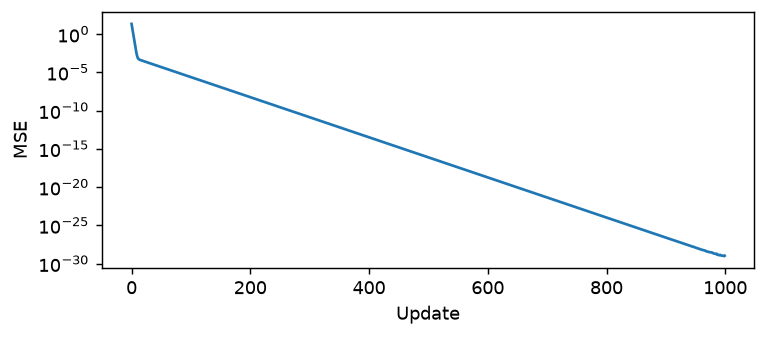

In [13]:
x = np.array([0.0, 1.0, 2.0, 3.0])
y = 2 * x + 1
a, b, lr = 0.0, 0.0, 0.05
loss_history = []
for _ in range(1000):
    error = a * x + b - y
    loss_history.append(np.mean(error**2))
    grad_a, grad_b = 2 * np.mean(error * x), 2 * np.mean(error)
    a -= lr * grad_a
    b -= lr * grad_b
print("Learned a,b:", a, b, "| Final MSE:", loss_history[-1])
plt.figure(figsize=(6, 2.7))
plt.plot(loss_history)
plt.xlabel("Update")
plt.ylabel("MSE")
plt.yscale("log")
plt.tight_layout()
plt.show()
np.testing.assert_allclose([a, b], [2, 1], atol=1e-5)
assert loss_history[-1] < loss_history[0]


## 기초 문제 13. Sigmoid와 binary cross entropy

**관련 강의:** L04·L07

1. logits에 sigmoid를 적용하고 BCE를 직접 계산하세요.
2. 정답 1인 샘플에 대한 예측 확률 0.9와 0.1의 손실을 비교하세요.


In [14]:
z = np.array([-2.0, 0.0, 2.0])
y = np.array([0.0, 1.0, 1.0])
p = 1 / (1 + np.exp(-z))
p_safe = np.clip(p, 1e-7, 1 - 1e-7)
bce = -np.mean(y * np.log(p_safe) + (1 - y) * np.log(1 - p_safe))
positive_losses = -np.log(np.array([0.9, 0.1]))
print("Sigmoid:", p, "| Mean BCE:", bce)
print("Positive-label loss for p=.9/.1:", positive_losses)
assert np.isclose(p[1], 0.5) and positive_losses[0] < positive_losses[1]


Sigmoid: [0.1192 0.5    0.8808] | Mean BCE: 0.31566773421529687
Positive-label loss for p=.9/.1: [0.1054 2.3026]


## 기초 문제 14. One-hot과 categorical cross entropy

**관련 강의:** L04·L07

1. 정수 정답을 3클래스 one-hot으로 바꾸세요.
2. one-hot 식과 정답 클래스 확률의 -log로 CCE를 구해 비교하세요.


In [15]:
labels = np.array([0, 2, 1])
prob = np.array([[0.8, 0.1, 0.1], [0.1, 0.2, 0.7], [0.2, 0.6, 0.2]])
one_hot = np.eye(3)[labels]
cce_one_hot = -np.mean(np.sum(one_hot * np.log(prob), axis=1))
cce_index = -np.mean(np.log(prob[np.arange(len(labels)), labels]))
print("One-hot:", one_hot, "| Mean CCE:", cce_one_hot)
np.testing.assert_allclose(cce_one_hot, cce_index)
np.testing.assert_array_equal(one_hot.argmax(axis=1), labels)


One-hot: [[1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]] | Mean CCE: 0.3635480396729776


## 기초 문제 15. Threshold와 분류 성능 지표

**관련 강의:** L04

1. threshold 0.3,0.5,0.7마다 예측 라벨과 TP,TN,FP,FN을 구하세요.
2. accuracy, precision, recall, F1을 직접 계산해 표로 출력하세요. 분모가 0이면 0으로 처리하세요.


In [16]:
y = np.array([0, 0, 1, 1, 1, 0])
prob = np.array([0.1, 0.4, 0.35, 0.8, 0.7, 0.6])
rows = []
for threshold in [0.3, 0.5, 0.7]:
    pred = (prob >= threshold).astype(int)
    tp = int(np.sum((y == 1) & (pred == 1)))
    tn = int(np.sum((y == 0) & (pred == 0)))
    fp = int(np.sum((y == 0) & (pred == 1)))
    fn = int(np.sum((y == 1) & (pred == 0)))
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * tp / max(2 * tp + fp + fn, 1)
    rows.append([threshold, tp, tn, fp, fn, (tp + tn) / len(y), precision, recall, f1])
print(
    pd.DataFrame(
        rows,
        columns=[
            "threshold",
            "TP",
            "TN",
            "FP",
            "FN",
            "accuracy",
            "precision",
            "recall",
            "F1",
        ],
    )
)
np.testing.assert_allclose(rows[1][1:5], [2, 2, 1, 1])
np.testing.assert_allclose(rows[1][-1], 2 / 3)


   threshold  TP  TN  FP  FN  accuracy  precision    recall        F1
0        0.3   3   1   2   0  0.666667   0.600000  1.000000  0.750000
1        0.5   2   2   1   1  0.666667   0.666667  0.666667  0.666667
2        0.7   2   3   0   1  0.833333   1.000000  0.666667  0.800000


## 기초 문제 16. Dense 순전파와 파라미터 수

**관련 강의:** L05

1. X @ W + b에 ReLU를 적용해 (2,4) 출력을 계산하세요.
2. 같은 W,b를 Keras Dense에 넣어 결과를 비교하고 파라미터 수를 구하세요.


In [17]:
X = np.array([[1.0, 2.0, 3.0], [-1.0, 0.0, 1.0]], dtype="float32")
W = np.arange(12, dtype="float32").reshape(3, 4) / 10
b = np.array([0.1, -0.2, 0.3, -0.4], dtype="float32")
manual = np.maximum(X @ W + b, 0)
dense = Dense(4, activation="relu")
dense.build((None, 3))
dense.set_weights([W, b])
keras_output = dense(X).numpy()
print("Output:", manual, "| Shape:", manual.shape)
print("Parameters:", W.size + b.size, "| Keras:", dense.count_params())
np.testing.assert_allclose(manual, keras_output, atol=1e-6)
assert dense.count_params() == 3 * 4 + 4


Output: [[3.3 3.6 4.7 4.6]
 [0.9 0.6 1.1 0.4]] | Shape: (2, 4)
Parameters: 16 | Keras: 16


## 기초 문제 17. Chain rule과 수치미분

**관련 강의:** L05

1. 입력→ReLU 은닉 뉴런→선형 출력에서 MSE의 네 파라미터 gradient를 구하세요.
2. 중앙 차분(epsilon=1e-6)으로 구한 수치미분과 비교하세요.


In [18]:
x, y = 2.0, 1.0
parameters = np.array([0.5, -0.1, -0.4, 0.2])
w1, b1, w2, b2 = parameters
z = w1 * x + b1
h = max(z, 0)
pred = w2 * h + b2
grad_output = 2 * (pred - y)
grad_hidden = grad_output * w2 * (z > 0)
manual = np.array([grad_hidden * x, grad_hidden, grad_output * h, grad_output])


def loss_for(p):
    w1, b1, w2, b2 = p
    return (w2 * max(w1 * x + b1, 0) + b2 - y) ** 2


epsilon = 1e-6
numeric = []
for i in range(4):
    plus, minus = parameters.copy(), parameters.copy()
    plus[i] += epsilon
    minus[i] -= epsilon
    numeric.append((loss_for(plus) - loss_for(minus)) / (2 * epsilon))
print("Backprop:", manual)
print("Numerical:", np.array(numeric))
np.testing.assert_allclose(manual, numeric, atol=1e-6)


Backprop: [ 1.856  0.928 -2.088 -2.32 ]
Numerical: [ 1.856  0.928 -2.088 -2.32 ]


## 기초 문제 18. GradientTape로 자동미분 확인

**관련 강의:** L05

1. w1=.5,b1=-.1,w2=-.4,b2=.2, 입력 2, 정답 1로 순전파하세요.
2. GradientTape로 네 gradient를 구하고 [1.856,.928,-2.088,-2.32]와 비교하세요.


In [19]:
w1 = tf.Variable(0.5)
b1 = tf.Variable(-0.1)
w2 = tf.Variable(-0.4)
b2 = tf.Variable(0.2)
with tf.GradientTape() as tape:
    hidden = tf.nn.relu(w1 * 2.0 + b1)
    prediction = w2 * hidden + b2
    loss = (prediction - 1.0) ** 2
gradients = tape.gradient(loss, [w1, b1, w2, b2])
values = np.array([g.numpy() for g in gradients])
print("Loss:", float(loss.numpy()), "| Gradients:", values)
np.testing.assert_allclose(values, [1.856, 0.928, -2.088, -2.32], atol=1e-5)


Loss: 1.345599889755249 | Gradients: [ 1.856  0.928 -2.088 -2.32 ]


## 기초 문제 19. Bernoulli MLE와 NLL

**관련 강의:** L07

1. 관측 [1,0,1,1,0]에서 확률 후보 0.1~0.9의 평균 NLL을 계산하세요.
2. NLL이 가장 작은 후보와 표본 평균을 비교하세요.


In [20]:
observed = np.array([1.0, 0.0, 1.0, 1.0, 0.0])
candidates = np.arange(0.1, 1.0, 0.1)
nll = np.array(
    [
        -np.mean(observed * np.log(p) + (1 - observed) * np.log(1 - p))
        for p in candidates
    ]
)
best = candidates[np.argmin(nll)]
print("Best probability:", best, "| Sample mean:", observed.mean())
print("Mean NLL:", nll)
np.testing.assert_allclose(best, 0.6)
np.testing.assert_allclose(best, observed.mean())


Best probability: 0.6 | Sample mean: 0.6
Mean NLL: [1.4237 1.0549 0.8651 0.7541 0.6931 0.673  0.6956 0.7777 0.9843]


## 기초 문제 20. KL divergence 구현

**관련 강의:** L07

1. KL(P||Q)=sum(P*log(P/Q))를 함수로 구현하세요.
2. P와 같은 분포, 가까운 분포, 다른 분포의 결과를 비교하세요.


In [21]:
P = np.array([0.7, 0.2, 0.1])
Q_near = np.array([0.6, 0.3, 0.1])
Q_far = np.array([0.1, 0.2, 0.7])


def kl_divergence(p, q):
    # 이번 입력은 모든 확률이 양수입니다.
    return np.sum(p * np.log(p / q))


same, near, far = [kl_divergence(P, q) for q in [P, Q_near, Q_far]]
print("Same / near / far KL:", same, near, far)
assert np.isclose(same, 0) and 0 < near < far


Same / near / far KL: 0.0 0.026812454257447993 1.1675460894331877


## 기초 문제 21. 배치 크기와 업데이트 횟수

**관련 강의:** L08

1. 샘플 10개를 batch_size 1,4,10으로 순회하세요.
2. 마지막 작은 배치도 포함해 1 epoch와 3 epoch의 업데이트 횟수를 계산하세요.


In [22]:
indices = np.arange(10)
rows = []
for batch_size in [1, 4, 10]:
    batches = [
        indices[start : start + batch_size]
        for start in range(0, len(indices), batch_size)
    ]
    updates = len(batches)
    rows.append([batch_size, [len(b) for b in batches], updates, 3 * updates])
print(
    pd.DataFrame(
        rows,
        columns=["batch_size", "batch_lengths", "updates_1_epoch", "updates_3_epochs"],
    )
)
assert rows[1][1] == [4, 4, 2]
assert [r[-1] for r in rows] == [30, 9, 3]


   batch_size  ... updates_3_epochs
0           1  ...               30
1           4  ...                9
2          10  ...                3

[3 rows x 4 columns]


## 기초 문제 22. Momentum 업데이트 직접 구현

**관련 강의:** L08

1. 매번 gradient=1인 상황에서 v=beta*v+gradient, w=w-lr*v를 세 번 계산하세요.
2. 초기 w=v=0, lr=.1로 beta=0,.5,.9의 결과를 비교하세요.


In [23]:
lr = 0.1
final_weights = []
for beta in [0.0, 0.5, 0.9]:
    w, v = 0.0, 0.0
    trace = []
    for _ in range(3):
        gradient = 1.0
        v = beta * v + gradient
        w -= lr * v
        trace.append(w)
    final_weights.append(w)
    print("beta:", beta, "| Weight history:", np.round(trace, 4))
np.testing.assert_allclose(final_weights, [-0.3, -0.425, -0.561])


beta: 0.0 | Weight history: [-0.1 -0.2 -0.3]
beta: 0.5 | Weight history: [-0.1   -0.25  -0.425]
beta: 0.9 | Weight history: [-0.1   -0.29  -0.561]


## 기초 문제 23. Warm-up과 cosine learning rate

**관련 강의:** L08

1. 0~10 step에서 처음 3 step은 선형 warm-up, 이후는 cosine으로 .1→.01이 되는 함수를 작성하세요.
2. 고정 LR=.1과 함께 그래프로 표시하세요.


Scheduled LR: [0.0333 0.0667 0.1    0.1    0.0955 0.0831 0.065  0.045  0.0269 0.0145
 0.01  ]


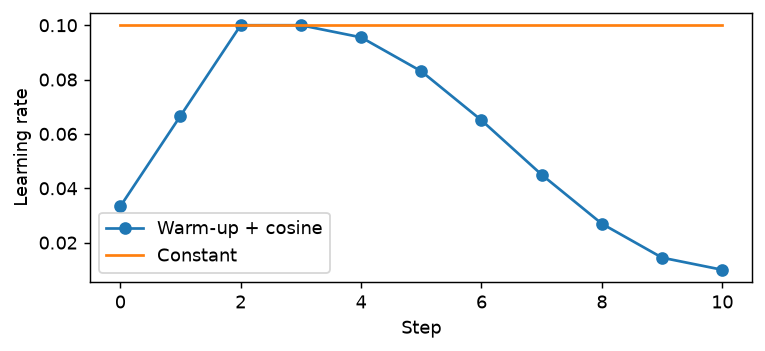

In [24]:
def learning_rate(step, total_steps=10, warmup_steps=3, peak=0.1, minimum=0.01):
    if step < warmup_steps:
        return peak * (step + 1) / warmup_steps
    progress = (step - warmup_steps) / (total_steps - warmup_steps)
    return minimum + 0.5 * (peak - minimum) * (1 + np.cos(np.pi * progress))


steps = np.arange(11)
scheduled = np.array([learning_rate(int(s)) for s in steps])
print("Scheduled LR:", scheduled)
plt.figure(figsize=(6, 2.8))
plt.plot(steps, scheduled, marker="o", label="Warm-up + cosine")
plt.plot(steps, np.full(len(steps), 0.1), label="Constant")
plt.xlabel("Step")
plt.ylabel("Learning rate")
plt.legend()
plt.tight_layout()
plt.show()
np.testing.assert_allclose(scheduled[[2, 3, 10]], [0.1, 0.1, 0.01])


## 기초 문제 24. 초기화와 layer별 activation 크기

**관련 강의:** L08

1. 입력 (1000,64)와 은닉층 4개에서 Xavier 표준편차 sqrt(1/fan_in), He sqrt(2/fan_in)를 적용하세요.
2. 같은 기본 난수 가중치에 두 배율을 적용하고 ReLU 출력의 층별 표준편차를 비교하세요.


In [25]:
rng = np.random.default_rng(42)
X = rng.normal(size=(1000, 64))
base_weights = [rng.normal(size=(64, 64)) for _ in range(4)]
for name, scale in [("Xavier", np.sqrt(1 / 64)), ("He", np.sqrt(2 / 64))]:
    h = X.copy()
    stds = []
    for base in base_weights:
        h = np.maximum(h @ (base * scale), 0)
        stds.append(h.std())
    print(name, "activation std:", np.round(stds, 4))
    assert np.isfinite(stds).all() and len(stds) == 4
# 이 값은 난수 입력을 넣은 크기 확인 결과이며 학습 성능 비교는 아닙니다.


Xavier activation std: [0.5877 0.4036 0.3006 0.2024]
He activation std: [0.8311 0.8072 0.8501 0.8095]


## 기초 문제 25. 활성함수와 도함수

**관련 강의:** L09

1. z=[-2,-1,0,1,2]에서 sigmoid,tanh,ReLU,Leaky ReLU(alpha=.1)의 출력과 도함수를 계산하세요.
2. 이번 문제에서 ReLU의 0에서 도함수는 0, Leaky ReLU의 0에서는 alpha로 정의하세요.


In [26]:
z = np.array([-2.0, -1.0, 0.0, 1.0, 2.0])
alpha = 0.1
sigmoid = 1 / (1 + np.exp(-z))
tanh = np.tanh(z)
relu = np.maximum(z, 0)
leaky = np.where(z > 0, z, alpha * z)
sigmoid_grad = sigmoid * (1 - sigmoid)
tanh_grad = 1 - tanh**2
relu_grad = (z > 0).astype(float)
leaky_grad = np.where(z > 0, 1.0, alpha)
print(
    pd.DataFrame(
        {
            "z": z,
            "sigmoid": sigmoid,
            "sigmoid_grad": sigmoid_grad,
            "tanh": tanh,
            "tanh_grad": tanh_grad,
            "ReLU": relu,
            "ReLU_grad": relu_grad,
            "LeakyReLU": leaky,
            "Leaky_grad": leaky_grad,
        }
    )
)
assert np.isclose(sigmoid_grad[2], 0.25)
assert np.all(relu_grad[z < 0] == 0) and np.all(leaky_grad[z < 0] == 0.1)


     z   sigmoid  sigmoid_grad  ...  ReLU_grad  LeakyReLU  Leaky_grad
0 -2.0  0.119203      0.104994  ...        0.0       -0.2         0.1
1 -1.0  0.268941      0.196612  ...        0.0       -0.1         0.1
2  0.0  0.500000      0.250000  ...        0.0        0.0         0.1
3  1.0  0.731059      0.196612  ...        1.0        1.0         1.0
4  2.0  0.880797      0.104994  ...        1.0        2.0         1.0

[5 rows x 9 columns]


## 기초 문제 26. 훈련 통계로 결측 대체·정규화·표준화

**관련 강의:** L09

1. 훈련 중앙값으로 훈련·검증의 NaN을 채우세요.
2. 훈련 통계만 사용해 MinMax와 표준화를 직접 구현하고 검증값에도 적용하세요.
3. 훈련 표준화의 평균·표준편차와 검증 MinMax 결과를 출력하세요.


In [27]:
train = np.array([[1.0, 10.0], [2.0, 20.0], [np.nan, 30.0], [4.0, 40.0]])
validation = np.array([[5.0, np.nan]])
median = np.nanmedian(train, axis=0)
train_filled = np.where(np.isnan(train), median, train)
val_filled = np.where(np.isnan(validation), median, validation)
minimum, maximum = train_filled.min(0), train_filled.max(0)
span = np.where(maximum > minimum, maximum - minimum, 1)
train_mm = (train_filled - minimum) / span
val_mm = (val_filled - minimum) / span
mean, std = train_filled.mean(0), train_filled.std(0)
std_safe = np.where(std > 0, std, 1)
train_z = (train_filled - mean) / std_safe
val_z = (val_filled - mean) / std_safe
print("Train medians:", median)
print("Train z mean/std:", train_z.mean(0), train_z.std(0))
print("Validation MinMax / standardized:", val_mm, val_z)
# 새 값이 훈련 범위를 벗어나면 MinMax 결과가 1보다 클 수 있습니다.
np.testing.assert_allclose(train_z.mean(0), 0, atol=1e-12)
np.testing.assert_allclose(train_z.std(0), 1)
np.testing.assert_allclose(val_mm, [[4 / 3, 0.5]])


Train medians: [ 2. 25.]
Train z mean/std: [-0.  0.] [1. 1.]
Validation MinMax / standardized: [[1.3333 0.5   ]] [[2.5236 0.    ]]


## 기초 문제 27. BatchNorm과 LayerNorm의 축

**관련 강의:** L09

1. Z의 열 방향 통계로 BatchNorm, 행 방향 통계로 LayerNorm을 직접 계산하세요.
2. epsilon=1e-5로 Keras의 scale/center 없는 출력과 비교하세요. BatchNorm은 training=True로 호출하세요.


In [28]:
Z = np.array([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]], dtype="float32")
epsilon = 1e-5
bn = (Z - Z.mean(axis=0, keepdims=True)) / np.sqrt(
    Z.var(axis=0, keepdims=True) + epsilon
)
ln = (Z - Z.mean(axis=1, keepdims=True)) / np.sqrt(
    Z.var(axis=1, keepdims=True) + epsilon
)
bn_layer = BatchNormalization(epsilon=epsilon, center=False, scale=False)
ln_layer = LayerNormalization(epsilon=epsilon, center=False, scale=False)
bn_tf = bn_layer(Z, training=True).numpy()
ln_tf = ln_layer(Z).numpy()
print("BatchNorm:", bn, "| Column mean:", bn.mean(axis=0))
print("LayerNorm:", ln, "| Row mean:", ln.mean(axis=1))
np.testing.assert_allclose(bn, bn_tf, atol=1e-6)
np.testing.assert_allclose(ln, ln_tf, atol=1e-6)


BatchNorm: [[-1. -1. -1.]
 [ 1.  1.  1.]] | Column mean: [0. 0. 0.]
LayerNorm: [[-1.2247  0.      1.2247]
 [-1.2247  0.      1.2247]] | Row mean: [0. 0.]


## 기초 문제 28. L1·L2 penalty와 AdamW weight decay

**관련 강의:** L10

1. 가중치 [2,-1,.5]와 lambda=.1에서 L1,L2 penalty를 직접 구해 Keras와 비교하세요.
2. 별도 가중치 2.0에 gradient=0, AdamW(lr=.1,weight_decay=.2)를 한 번 적용해 변화를 확인하세요.


In [29]:
weights = np.array([2.0, -1.0, 0.5], dtype="float32")
coefficient = 0.1
l1_penalty = coefficient * np.sum(np.abs(weights))
l2_penalty = coefficient * np.sum(weights**2)
print("L1 / L2 penalty:", l1_penalty, l2_penalty)
np.testing.assert_allclose(l1_penalty, float(l1(coefficient)(weights)), rtol=1e-6)
np.testing.assert_allclose(l2_penalty, float(l2(coefficient)(weights)), rtol=1e-6)
weight = tf.Variable(2.0)
optimizer = AdamW(learning_rate=0.1, weight_decay=0.2)
optimizer.apply_gradients([(tf.zeros_like(weight), weight)])
print("Weight with zero task gradient: 2.0 ->", float(weight.numpy()))
# 이번 zero-gradient 예시에서는 w_new=(1-lr*weight_decay)*w입니다.
np.testing.assert_allclose(weight.numpy(), 2 * (1 - 0.1 * 0.2), atol=1e-6)


L1 / L2 penalty: 0.35 0.52500004
Weight with zero task gradient: 2.0 -> 1.9600000381469727


## 기초 문제 29. Dropout의 학습·추론 출력

**관련 강의:** L10

1. 1로 채운 (2,8) 입력에 rate=.5 Dropout을 적용하세요.
2. training=True와 False의 결과를 출력하고 학습 출력에 0 또는 2가 나오는지 확인하세요.


Training output: [[0. 0. 2. 0. 0. 2. 2. 0.]
 [0. 0. 2. 0. 0. 0. 2. 2.]]
Inference output: [[1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1.]]


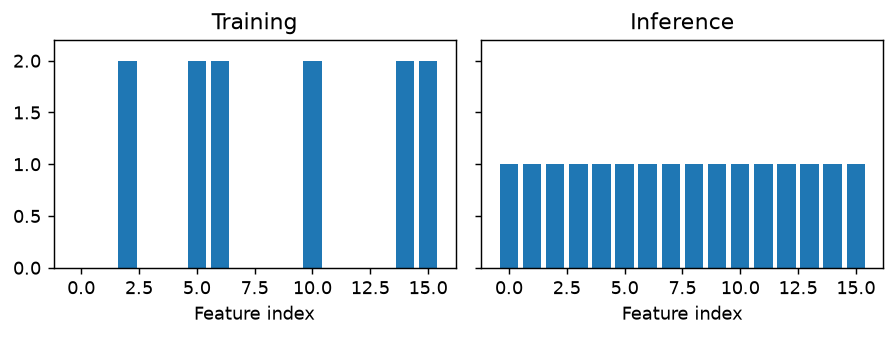

In [30]:
X = np.ones((2, 8), dtype="float32")
layer = Dropout(rate=0.5, seed=42)
training = layer(X, training=True).numpy()
inference = layer(X, training=False).numpy()
print("Training output:", training)
print("Inference output:", inference)
fig, axes = plt.subplots(1, 2, figsize=(7, 2.7), sharey=True)
axes[0].bar(range(16), training.ravel())
axes[0].set_title("Training")
axes[1].bar(range(16), inference.ravel())
axes[1].set_title("Inference")
for ax in axes:
    ax.set_ylim(0, 2.2)
    ax.set_xlabel("Feature index")
fig.tight_layout()
plt.show()
assert np.all(np.isclose(training, 0) | np.isclose(training, 2))
np.testing.assert_array_equal(inference, X)


## 기초 문제 30. EarlyStopping 규칙을 반복문으로 구현

**관련 강의:** L06·L10

1. 주어진 검증 손실에서 개선이 없으면 wait를 늘리고 개선되면 0으로 초기화하세요.
2. patience=2에서 중단 epoch와 best epoch를 구하고 best 가중치를 복원하세요.
3. 가중치는 epoch마다 [epoch,-epoch]라고 가정합니다. 손실 목록은 규칙 확인용 입력입니다.


In [31]:
# 실제 학습 결과가 아니라 조기 종료 규칙을 확인하기 위해 지정한 손실입니다.
validation_losses = [0.8, 0.6, 0.4, 0.42, 0.45, 0.39]
patience = 2
best_loss = np.inf
wait = 0
best_epoch = 0
best_weights = None
for epoch, val_loss in enumerate(validation_losses, start=1):
    weights = np.array([epoch, -epoch])
    if val_loss < best_loss:
        best_loss = val_loss
        best_epoch = epoch
        best_weights = weights.copy()
        wait = 0
    else:
        wait += 1
    if wait >= patience:
        break
stop_epoch = epoch
restored_weights = best_weights.copy()
print("Stop epoch:", stop_epoch, "| Best epoch/loss:", best_epoch, best_loss)
print("Weights at stop:", weights, "| Restored best:", restored_weights)
assert stop_epoch == 5 and best_epoch == 3
np.testing.assert_array_equal(restored_weights, [3, -3])


Stop epoch: 5 | Best epoch/loss: 3 0.4
Weights at stop: [ 5 -5] | Restored best: [ 3 -3]
